# 03 · Confidence calibration (ROC) for the slow-readback threshold τ

**Owner:** Saad (Pillar III) · **Runs on:** Colab or a local laptop CPU (a few seconds)

**Question.** The app reads a word slowly (140 WPM instead of 200 WPM) when its ASR confidence is below τ.
We have used τ = 0.90 as a placeholder. Which τ best separates words Whisper got **wrong** from words it got **right**?

**Method.** Ali ran his 40 test recordings through `ASREngine` and exported one row per recognised word
(clip id, word, confidence, and a `correct` flag from aligning against the reference prompt). If that flag is missing,
this notebook aligns each transcript to its prompt itself. Either way every word is *correct* or *error*, then treat "confidence < τ" as a detector of errors and sweep τ to draw the ROC curve.
Sensitivity = share of errors that get flagged. Specificity = share of correct words that are left alone.
We pick τ by Youden's J (sensitivity + specificity − 1), check how stable it is with a bootstrap, and estimate the cost in extra listening time.

**Inputs**
1. `data/academic_vocab_prompts.csv` (columns `id, domain, split, text`; the 40 `test` rows are the reference text)
2. Ali's per-word confidence export (set `CONF_CSV` below)

**If you run this in Colab:** upload both CSVs in the Files panel (or mount Drive) and change the two paths in the next cell.

> If `CONF_CSV` does not exist yet, the notebook runs on **synthetic demo data** so you can check that everything works. A loud banner is printed. **Never report numbers from demo mode.**

In [1]:
import os, json, string, difflib
from pathlib import Path

# Jupyter/VS Code start notebooks inside their own folder. Step up to the repo root so "data/..." paths work.
if not Path("data/academic_vocab_prompts.csv").exists() and Path("../data/academic_vocab_prompts.csv").exists():
    os.chdir("..")
print("working directory:", Path.cwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------- CONFIG: edit these -------------------------
CONF_CSV        = "data/word_confidences_test.csv"   # Ali's per-word export (both models, both confidence modes)
MODEL           = "lora"        # which model's rows to calibrate on (None = use every row)
CONFIDENCE_COLUMN = "conf_geo"  # "conf_geo" = ASREngine default (conf_mode="geo"); "conf_min" = mode "min"
PROMPTS_CSV     = "data/academic_vocab_prompts.csv"  # id, domain, split, text
CURRENT_TAU     = 0.90   # placeholder used so far (Pillar III execution contract)
MIN_SENSITIVITY = 0.80   # for the "safety-first" alternative operating point
NORMAL_WPM, SLOW_WPM = 200, 140
N_BOOT, SEED    = 1000, 42
OUT_JSON        = "data/calibration_results.json"
OUT_PNG         = "roc_calibration.png"

# Column names to look for in Ali's file (first match wins). Add yours if they differ.
PROMPT_COLS  = ["prompt_id", "clip_id", "id", "utterance_id", "audio_id", "file", "filename"]
WORD_COLS    = ["word", "token", "hyp_word"]
CONF_COLS    = [CONFIDENCE_COLUMN, "confidence", "conf", "word_confidence", "score"]
CORRECT_COLS = ["is_correct", "correct"]   # optional: skips alignment if Ali already labelled words

rng = np.random.default_rng(SEED)
PUNCT = string.punctuation + " "
def norm(w): return str(w).strip(PUNCT).lower()

working directory: /home/larry/Projects/verbascribe-exam


## 1 · Load the reference prompts and the confidence export

In [2]:
prompts = pd.read_csv(PROMPTS_CSV)
test_prompts = prompts[prompts["split"] == "test"].set_index("id")["text"].to_dict()
print(f"{len(test_prompts)} test prompts loaded (expected 40)")

def make_demo_confidences(test_prompts, error_rate=0.12):
    """SYNTHETIC stand-in for Ali's file. Errors get lower confidence on average; nothing here is real."""
    rows = []
    for pid, text in test_prompts.items():
        for w in text.split():
            if rng.random() < error_rate:
                rows.append((pid, "zzzz", float(rng.beta(5, 3))))     # misrecognised word
            else:
                rows.append((pid, w, float(rng.beta(30, 1.5))))       # correct word
    return pd.DataFrame(rows, columns=["prompt_id", "word", "confidence"])

DEMO = not Path(CONF_CSV).exists()
if DEMO:
    print("=" * 74)
    print(f"  {CONF_CSV} NOT FOUND -> running on SYNTHETIC DEMO DATA.")
    print("  These results mean nothing. Do not copy any number into the report or app.")
    print("=" * 74)
    raw = make_demo_confidences(test_prompts)
else:
    raw = pd.read_csv(CONF_CSV)
    print(f"Loaded {len(raw)} rows from {CONF_CSV}; columns: {list(raw.columns)}")
    if MODEL is not None and "model" in raw.columns:
        raw = raw[raw["model"] == MODEL].reset_index(drop=True)
        print(f"Keeping model = {MODEL!r}: {len(raw)} rows, using confidence column {CONFIDENCE_COLUMN!r}")

def pick(df, names, what):
    for n in names:
        if n in df.columns:
            return n
    raise KeyError(f"Could not find a {what} column. Looked for {names}, the file has {list(df.columns)}. "
                   f"Add the right name to the *_COLS lists in the config cell.")

pcol, wcol, ccol = pick(raw, PROMPT_COLS, "prompt id"), pick(raw, WORD_COLS, "word"), pick(raw, CONF_COLS, "confidence")
okcol = next((c for c in CORRECT_COLS if c in raw.columns), None)

df = pd.DataFrame({"prompt_id": raw[pcol], "word": raw[wcol].astype(str), "confidence": raw[ccol].astype(float)})
if okcol is not None:
    df["is_correct"] = raw[okcol].astype(bool)

# Allow file names such as "17.wav" or "test_017.wav": take the number in the name as the prompt id.
if not pd.api.types.is_numeric_dtype(df["prompt_id"]):
    ids = df["prompt_id"].astype(str).str.extract(r"(\d+)", expand=False)
    if ids.isna().any():
        raise ValueError("Some prompt ids contain no number, so they cannot be matched to the prompts CSV.")
    df["prompt_id"] = ids.astype(int)

df = df[df["word"].map(norm) != ""].reset_index(drop=True)
if not df["confidence"].between(0, 1).all():
    print("WARNING: some confidences are outside [0, 1]. Check Ali's export.")
print(f"{len(df)} recognised words across {df['prompt_id'].nunique()} utterances")

40 test prompts loaded (expected 40)
Loaded 885 rows from data/word_confidences_test.csv; columns: ['clip_id', 'model', 'word', 'conf_geo', 'conf_min', 'correct']
Keeping model = 'lora': 441 rows, using confidence column 'conf_geo'
441 recognised words across 40 utterances


## 2 · Label each recognised word as correct or error

We align the recognised words to the reference prompt with `difflib` (a standard sequence alignment, so no extra install).
A recognised word is **correct** if it lines up with an identical reference word. A substituted or inserted word is an **error**.
Words the recogniser *dropped* have no confidence score, so they cannot be flagged. They are counted separately as a limitation.

In [3]:
def label_words(df):
    if "is_correct" in df.columns:                       # Ali already labelled the words
        return df.assign(is_error=~df["is_correct"]), 0
    parts, missed = [], 0
    for pid, g in df.groupby("prompt_id", sort=False):
        if pid not in test_prompts:
            print(f"  skipping prompt id {pid}: not a test prompt")
            continue
        ref = [norm(w) for w in test_prompts[pid].split()]
        hyp = [norm(w) for w in g["word"]]
        ok = np.zeros(len(hyp), dtype=bool)
        for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, ref, hyp, autojunk=False).get_opcodes():
            if tag == "equal":
                ok[j1:j2] = True
            elif tag == "delete":
                missed += i2 - i1
            elif tag == "replace":                      # e.g. 2 reference words heard as 1 word
                missed += max(0, (i2 - i1) - (j2 - j1))
        parts.append(g.assign(is_error=~ok))
    return pd.concat(parts, ignore_index=True), missed

lab, missed_ref_words = label_words(df)
conf, err = lab["confidence"].to_numpy(float), lab["is_error"].to_numpy(bool)

n_err, n_ok = int(err.sum()), int((~err).sum())
print(f"words scored: {len(lab)} | errors: {n_err} ({n_err/len(lab):.1%}) | correct: {n_ok}")
print(f"reference words the recogniser dropped (cannot be flagged): {missed_ref_words}")
if n_err == 0 or n_ok == 0:
    raise ValueError("Need both correct and erroneous words to draw a ROC curve.")
if n_err < 30:
    print(f"NOTE: only {n_err} errors, so the chosen tau will be noisy. Read the bootstrap interval below.")

lab.groupby("is_error")["confidence"].describe().round(3)

words scored: 441 | errors: 38 (8.6%) | correct: 403
reference words the recogniser dropped (cannot be flagged): 0


,count,mean,std,min,25%,50%,75%,max
is_error,,,,,,,,
False,403.0,0.942,0.113,0.308,0.949,0.988,0.994,1.000
True,38.0,0.675,0.233,0.199,0.538,0.692,0.881,0.993


## 3 · ROC sweep and choice of τ

A word is **flagged** (read slowly) when `confidence < τ`. We try every τ that falls between two observed confidence values.

In [4]:
def roc_arrays(conf, is_err):
    c_err, c_ok = np.sort(conf[is_err]), np.sort(conf[~is_err])
    u = np.unique(conf)
    taus = np.concatenate(([0.0], (u[:-1] + u[1:]) / 2, [1.0 + 1e-9]))   # 0 = flag nothing, >1 = flag everything
    tp = np.searchsorted(c_err, taus, side="left")                        # errors with conf < tau
    fp = np.searchsorted(c_ok,  taus, side="left")                        # correct words with conf < tau
    sens, fpr = tp / len(c_err), fp / len(c_ok)
    return taus, sens, 1 - fpr, fpr, (tp + fp) / len(conf)

def roc_table(conf, is_err):
    taus, sens, spec, fpr, flagged = roc_arrays(conf, is_err)
    return pd.DataFrame({"tau": taus, "sensitivity": sens, "specificity": spec, "fpr": fpr, "flagged_frac": flagged})

def metrics_at(conf, is_err, tau):
    flag = conf < tau
    sens, spec = flag[is_err].mean(), (~flag[~is_err]).mean()
    frac = flag.mean()
    return {"tau": round(float(tau), 3), "sensitivity": sens, "specificity": spec, "youden_J": sens + spec - 1,
            "words_flagged": frac,
            "extra_listening_time": frac * (NORMAL_WPM / SLOW_WPM - 1)}   # slowed words take 200/140 = 1.43x as long

tab = roc_table(conf, err)
_trapz = getattr(np, "trapezoid", None) or np.trapz
auc = float(_trapz(tab["sensitivity"], tab["fpr"]))
print(f"AUC = {auc:.3f}   (0.5 = confidence tells us nothing, 1.0 = perfect separation)")

# 1) Youden-optimal: best balance of sensitivity and specificity
best = (tab["sensitivity"] + tab["specificity"]).idxmax()
tau_youden = round(float(tab.loc[best, "tau"]), 2)

# 2) Safety-first: lowest tau that still catches at least MIN_SENSITIVITY of the errors
cand = tab[tab["sensitivity"] >= MIN_SENSITIVITY]
tau_safety = float(np.ceil(cand["tau"].min() * 100) / 100)    # round UP so the target still holds

points = {
    f"Current default (tau={CURRENT_TAU:.2f})": metrics_at(conf, err, CURRENT_TAU),
    "Youden-optimal": metrics_at(conf, err, tau_youden),
    f"Safety-first (sensitivity >= {MIN_SENSITIVITY:.0%})": metrics_at(conf, err, tau_safety),
}
summary = pd.DataFrame.from_dict(points, orient="index")
summary.round(3)

AUC = 0.885   (0.5 = confidence tells us nothing, 1.0 = perfect separation)


,tau,sensitivity,specificity,youden_J,words_flagged,extra_listening_time
Current default (tau=0.90),0.90,0.789,0.854,0.643,0.202,0.086
Youden-optimal,0.93,0.868,0.804,0.672,0.254,0.109
Safety-first (sensitivity >= 80%),0.91,0.816,0.839,0.654,0.218,0.093


**Reading the table.** `words_flagged` is the share of all words that would be slowed. `extra_listening_time` converts that
into extra time to hear the answer read back, using the same 200/140 WPM figures as the app. A higher τ catches more errors
but slows more correct words too.

In [5]:
# Informational: does "geo" or "min" confidence separate errors better? (the analysis above uses CONFIDENCE_COLUMN)
candidates = [c for c in ["conf_geo", "conf_min"] if c in raw.columns]
if okcol is not None and len(candidates) > 1:
    sub = raw[raw[wcol].map(norm) != ""]
    e_sub = ~sub[okcol].astype(bool).to_numpy()
    rows = []
    for c in candidates:
        t_c = roc_table(sub[c].to_numpy(float), e_sub)
        j = (t_c["sensitivity"] + t_c["specificity"]).idxmax()
        rows.append({"confidence_column": c, "AUC": float(_trapz(t_c["sensitivity"], t_c["fpr"])),
                     "youden_tau": round(float(t_c.loc[j, "tau"]), 2)})
    display(pd.DataFrame(rows).round(3))
else:
    print("Only one confidence column available, nothing to compare.")

,confidence_column,AUC,youden_tau
0,conf_geo,0.885,0.93
1,conf_min,0.893,0.88


## 4 · How stable is τ? (bootstrap over utterances)

With only 40 recordings, one unusual utterance could move the optimum. We resample whole utterances with replacement
and recompute the Youden-optimal τ each time.

In [6]:
groups = {pid: (g["confidence"].to_numpy(float), g["is_error"].to_numpy(bool)) for pid, g in lab.groupby("prompt_id")}
pids = np.array(list(groups))

boot = []
for _ in range(N_BOOT):
    pick_ids = rng.choice(pids, size=len(pids), replace=True)
    c = np.concatenate([groups[p][0] for p in pick_ids])
    e = np.concatenate([groups[p][1] for p in pick_ids])
    if e.sum() == 0 or (~e).sum() == 0:
        continue
    taus_b, sens_b, spec_b, _, _ = roc_arrays(c, e)
    boot.append(taus_b[np.argmax(sens_b + spec_b)])

lo, med, hi = np.percentile(boot, [2.5, 50, 97.5])
print(f"Youden-optimal tau over {len(boot)} resamples: median {med:.2f}, 95% interval [{lo:.2f}, {hi:.2f}]")
print(f"Point estimate on the full data: {tau_youden:.2f}")
if hi - lo > 0.15:
    print("The interval is wide: the data cannot pin tau down precisely. Say so in the report, and consider the safety-first value.")

Youden-optimal tau over 1000 resamples: median 0.92, 95% interval [0.83, 0.93]
Point estimate on the full data: 0.93


## 5 · Plots (saved for the report)

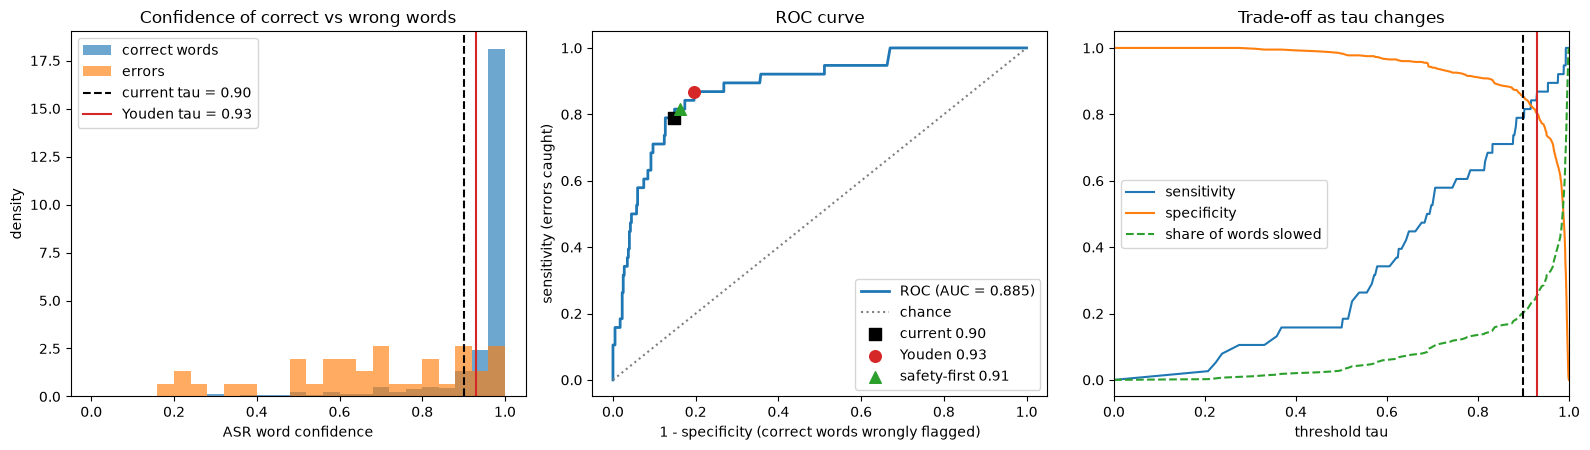

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) confidence distributions
bins = np.linspace(0, 1, 26)
ax[0].hist(conf[~err], bins=bins, alpha=0.65, density=True, label="correct words")
ax[0].hist(conf[err],  bins=bins, alpha=0.65, density=True, label="errors")
ax[0].axvline(CURRENT_TAU, color="k", ls="--", label=f"current tau = {CURRENT_TAU:.2f}")
ax[0].axvline(tau_youden, color="tab:red", ls="-", label=f"Youden tau = {tau_youden:.2f}")
ax[0].set(xlabel="ASR word confidence", ylabel="density", title="Confidence of correct vs wrong words"); ax[0].legend()

# (b) ROC
ax[1].plot(tab["fpr"], tab["sensitivity"], lw=2, label=f"ROC (AUC = {auc:.3f})")
ax[1].plot([0, 1], [0, 1], color="grey", ls=":", label="chance")
for label, t, colr, mk in [(f"current {CURRENT_TAU:.2f}", CURRENT_TAU, "k", "s"),
                           (f"Youden {tau_youden:.2f}", tau_youden, "tab:red", "o"),
                           (f"safety-first {tau_safety:.2f}", tau_safety, "tab:green", "^")]:
    m = metrics_at(conf, err, t)
    ax[1].scatter(1 - m["specificity"], m["sensitivity"], c=colr, marker=mk, s=70, zorder=3, label=label)
ax[1].set(xlabel="1 - specificity (correct words wrongly flagged)", ylabel="sensitivity (errors caught)", title="ROC curve"); ax[1].legend(loc="lower right")

# (c) sensitivity / specificity vs tau
ax[2].plot(tab["tau"], tab["sensitivity"], label="sensitivity")
ax[2].plot(tab["tau"], tab["specificity"], label="specificity")
ax[2].plot(tab["tau"], tab["flagged_frac"], ls="--", label="share of words slowed")
ax[2].axvline(tau_youden, color="tab:red"); ax[2].axvline(CURRENT_TAU, color="k", ls="--")
ax[2].set(xlim=(0, 1), xlabel="threshold tau", title="Trade-off as tau changes"); ax[2].legend()

if DEMO:
    fig.suptitle("SYNTHETIC DEMO DATA - NOT REAL RESULTS", color="red", fontsize=14, fontweight="bold")
fig.tight_layout(); fig.savefig(OUT_PNG, dpi=150); plt.show()

## 6 · Decide and save

`CHOSEN_TAU` below defaults to the Youden-optimal value. Change it if you prefer the safety-first value
(for a student who cannot easily re-listen, missing an error may matter more than a few extra seconds of listening). Justify the choice in the report.

In [8]:
CHOSEN_TAU = tau_youden          # <- or tau_safety, or a value of your own

chosen = metrics_at(conf, err, CHOSEN_TAU)
results = {
    "synthetic_demo_data": DEMO,
    "n_words": int(len(lab)), "n_errors": n_err, "n_utterances": int(len(groups)),
    "reference_words_dropped_by_asr": int(missed_ref_words),
    "auc": round(auc, 4),
    "tau_youden": tau_youden, "tau_safety_first": tau_safety, "min_sensitivity_target": MIN_SENSITIVITY,
    "tau_youden_bootstrap_95ci": [round(float(lo), 3), round(float(hi), 3)],
    "chosen_tau": CHOSEN_TAU,
    "chosen_metrics": {k: round(float(v), 4) for k, v in chosen.items()},
    "current_default_metrics": {k: round(float(v), 4) for k, v in points[list(points)[0]].items()},
}
Path(OUT_JSON).parent.mkdir(parents=True, exist_ok=True)
Path(OUT_JSON).write_text(json.dumps(results, indent=2))
print(json.dumps(results, indent=2))

if DEMO:
    print("\nDEMO MODE: do NOT change the app threshold based on this run.")
else:
    print(f"\nNext step: set TAU_DEFAULT = {CHOSEN_TAU:.2f} in app.py (and the default tau in AnswerStateMachine), then re-test the demo.")

{
  "synthetic_demo_data": false,
  "n_words": 441,
  "n_errors": 38,
  "n_utterances": 40,
  "reference_words_dropped_by_asr": 0,
  "auc": 0.8845,
  "tau_youden": 0.93,
  "tau_safety_first": 0.91,
  "min_sensitivity_target": 0.8,
  "tau_youden_bootstrap_95ci": [
    0.834,
    0.931
  ],
  "chosen_tau": 0.93,
  "chosen_metrics": {
    "tau": 0.93,
    "sensitivity": 0.8684,
    "specificity": 0.804,
    "youden_J": 0.6724,
    "words_flagged": 0.254,
    "extra_listening_time": 0.1088
  },
  "current_default_metrics": {
    "tau": 0.9,
    "sensitivity": 0.7895,
    "specificity": 0.8536,
    "youden_J": 0.6431,
    "words_flagged": 0.2018,
    "extra_listening_time": 0.0865
  }
}

Next step: set TAU_DEFAULT = 0.93 in app.py (and the default tau in AnswerStateMachine), then re-test the demo.
